# Geração Automática de Regras Fuzzy

### Aprendendo a base de regras a partir dos dados — método de Wang-Mendel

Até aqui, as regras de um sistema fuzzy vinham de um **especialista**. Neste
notebook elas vêm dos **dados**.

O pacote usado é o [`fuzzyTSmodel`](https://github.com/LAII-UFPB/fuzzyTSmodel):

```bash
uv pip install -e .
```


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from fuzzytsmodel import FuzzyTSModel, FuzzyRuleManager, FuzzyVariableManager

plt.rcParams["figure.figsize"] = (10, 3.5)
plt.rcParams["axes.grid"] = True

---
## 1. O problema

Regra escrita por um especialista:

> SE a distância é **pequena** E o ângulo é **grande**, ENTÃO a potência é **média**.

Isso funciona quando alguém sabe explicar o processo. Mas e quando temos apenas
**medições**, sem ninguém que saiba descrever a regra?

A ideia de Wang-Mendel: **cada amostra dos dados é uma regra em potencial.**

Vamos usar uma série temporal — prever o próximo valor a partir dos três anteriores:

$$\hat{y}_k = f(y_{k-1},\ y_{k-2},\ y_{k-3})$$


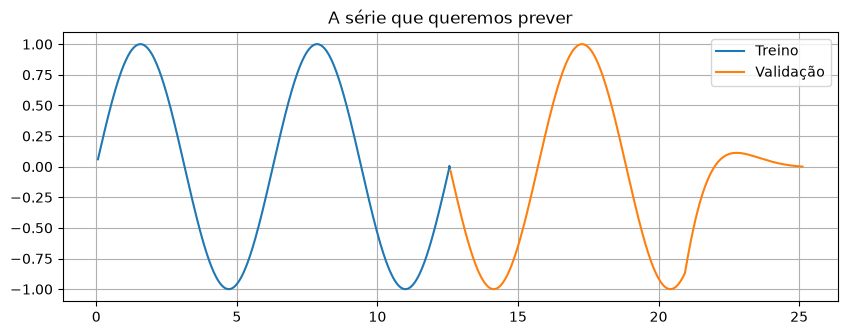

X tem shape (1254, 3)  (amostras, variáveis de entrada)
y tem shape (1254,)


In [3]:
N_LAGS = 3

t = np.arange(0, 8 * np.pi, 0.02)
meio, dois_tercos = len(t) // 2, len(t) // 2 + len(t) // 3

# tres regimes diferentes: seno, seno invertido e seno amortecido
y = np.concatenate([
    np.sin(t[:meio]),
    -np.sin(t[meio:dois_tercos]),
    -np.exp(-(t[dois_tercos:] - t[dois_tercos])) * np.sin(t[dois_tercos:]),
])

X = np.vstack([np.roll(y, lag) for lag in range(1, N_LAGS + 1)]).T
X, y, t = X[N_LAGS:], y[N_LAGS:], t[N_LAGS:]

corte = len(t) // 2
X_treino, y_treino = X[:corte], y[:corte]
X_val, y_val = X[corte:], y[corte:]

plt.plot(t[:corte], y_treino, label="Treino")
plt.plot(t[corte:], y_val, label="Validação")
plt.title("A série que queremos prever")
plt.legend(); plt.show()

print(f"X tem shape {X.shape}  (amostras, variáveis de entrada)")
print(f"y tem shape {y.shape}")

Cada **linha** de `X` é uma amostra, e vai virar uma regra.

In [3]:
for i in [0, 1, 2]:
    print(f"amostra {i}: entradas = {np.round(X_treino[i], 3)}  ->  saída = {y_treino[i]:.3f}")

amostra 0: entradas = [0.04 0.02 0.  ]  ->  saída = 0.060
amostra 1: entradas = [0.06 0.04 0.02]  ->  saída = 0.080
amostra 2: entradas = [0.08 0.06 0.04]  ->  saída = 0.100


---

Referência original: Wang & Mendel, *"Generating fuzzy rules by learning from examples"*,
IEEE Trans. SMC, 1992. Nos slides: 381–397.

**Dados:** uma tabela de exemplos `(x1, x2, ..., y)`

### Passo 1 — Dividir os domínios em regiões fuzzy
Para cada variável (entradas **e** saída), pega o intervalo [mín, máx] e divide em **2N+1
regiões** triangulares igualmente espaçadas. N é um parâmetro seu.

Com **N = 2** → 5 regiões: `S2, S1, CE, B1, B2`
Com **N = 6** → 13 regiões: `S6, S5, S4, S3, S2, S1, CE, B1, B2, B3, B4, B5, B6`

(`S` = *Small*, `B` = *Big*, `CE` = Center.) 

Os triângulos se sobrepõem: o pico de um é o início
do próximo: $ min + k·(max−min)/2N $, com k = 0, 1, …, 2N

### Passo 2 — Gerar uma regra para cada amostra
Para cada linha de dados, e para cada variável, calcula o grau de pertinência em cada região e
**fica com a região de maior grau**. Juntando as escolhas, sai uma regra.

Exemplo: `x1 = 0,5 → B1`, `x2 = −0,9 → S2`, `y = 0,1 → CE` ⟹
`SE (x1 é B1) E (x2 é S2) ENTÃO (y é CE)`.

### Passo 3 — Atribuir um peso a cada regra
O peso é o **produto** dos graus de pertinência das regiões escolhidas.
Se os graus foram 0,8 · 0,7 · 0,9, o peso é **0,504** (slides 393).

Intuição: o peso mede **o quão "típica" é a amostra** para aquela regra. Uma amostra que cai
bem no centro de todas as regiões gera regra de peso alto; uma que cai na fronteira entre duas
regiões gera regra de peso baixo — e provavelmente menos confiável.

### Passo 4 — Resolver conflitos e redundâncias
Com centenas de amostras, duas podem gerar **o mesmo antecedente**:
- **Mesmo consequente** → regras idênticas (redundância) → fica uma.
- **Consequentes diferentes** → **conflito** → **fica a de maior peso**.

Resultado: uma base de regras **sem contradições**, menor que o número de amostras.

### Depois disso
A base de regras entra no sistema de inferência Mamdani e está pronto para prever.


---
## 2. Passo 1 — dividir os domínios em regiões fuzzy

Cada variável tem seu domínio dividido em **2N+1 regiões** triangulares com nomes: `S` de *Small*, `B` de *Big*, `CE` de *Center*.

Com `N=2`, são 5 regiões: `S2, S1, CE, B1, B2`.


In [4]:
from fuzzytsmodel import region_terms

for N in (2, 3, 6):
    print(f"N = {N}  ->  {2*N+1} regiões: {region_terms(N)}")

N = 2  ->  5 regiões: ['S2', 'S1', 'CE', 'B1', 'B2']
N = 3  ->  7 regiões: ['S3', 'S2', 'S1', 'CE', 'B1', 'B2', 'B3']
N = 6  ->  13 regiões: ['S6', 'S5', 'S4', 'S3', 'S2', 'S1', 'CE', 'B1', 'B2', 'B3', 'B4', 'B5', 'B6']


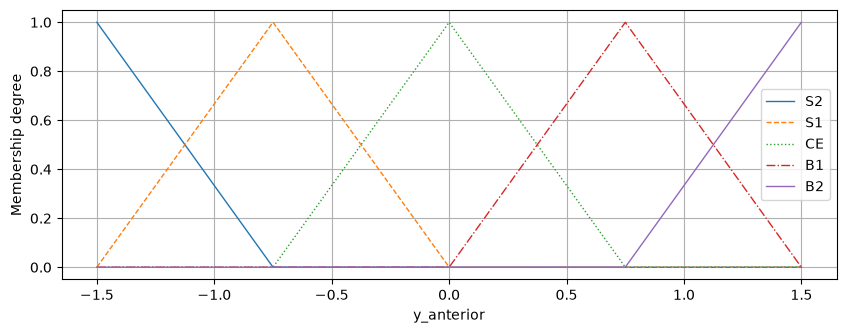

In [5]:
mgr = FuzzyVariableManager(N=2, input_range=[-1.5, 1.5], output_range=[-1.5, 1.5])
var_demo = mgr.create_variable("y_anterior")
var_demo.plot()

**N é o parâmetro mais importante do método**: ele controla
a granularidade com que o espaço é descrito.

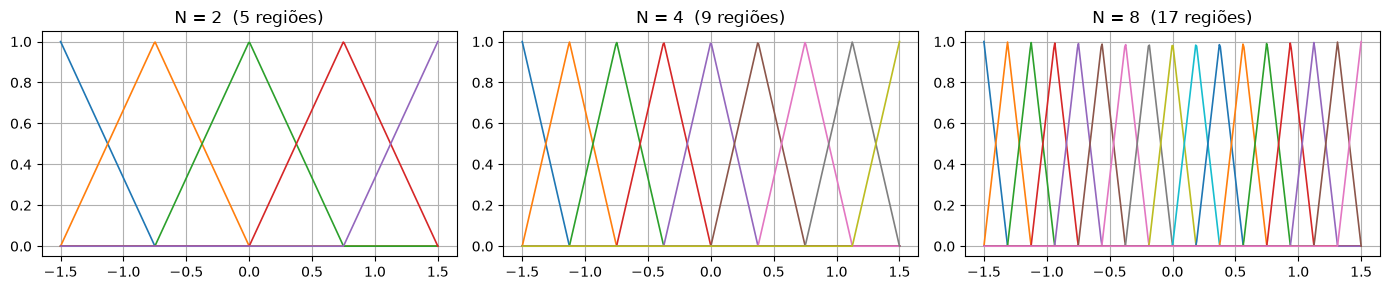

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3))
for ax, N in zip(axes, (2, 4, 8)):
    universo = np.linspace(-1.5, 1.5, 400)
    v = FuzzyVariableManager(N=N, input_range=[-1.5, 1.5],
                             output_range=[-1.5, 1.5]).create_variable("x")
    for termo in region_terms(N):
        ax.plot(universo, [v.get_values(u)[termo] for u in universo], lw=1.2)
    ax.set_title(f"N = {N}  ({2*N+1} regiões)")
plt.tight_layout(); plt.show()

> N baixo → poucas regras, modelo suave.
> N alto → mais detalhe, mais regras, risco de decorar o ruído.

---
## 3. Passo 2 — uma regra para cada amostra

Para um valor, calculamos o grau de pertinência em **cada** região e ficamos com
a de **maior grau**.


In [7]:
valor = 0.5
graus = var_demo.get_values(valor)

for termo, grau in graus.items():
    barra = "█" * int(grau * 30)
    print(f"  {termo:>3}: {grau:.3f} {barra}")

termo_forte, grau_forte = FuzzyRuleManager.strong_pertinence(var_demo, valor)
print(f"\n-> {valor} é considerado '{termo_forte}' (grau {grau_forte:.3f})")

   S2: 0.000 
   S1: 0.000 
   CE: 0.333 ██████████
   B1: 0.667 ████████████████████
   B2: 0.000 

-> 0.5 é considerado 'B1' (grau 0.667)


Fazendo isso para as **três entradas e a saída** de uma amostra, sai a regra:

In [6]:
mgr6 = FuzzyVariableManager(N=6, input_range=[-1.5, 1.5], output_range=[-1.5, 1.5])
entradas = [mgr6.create_variable(f"y_k_menos_{i}") for i in (1, 2, 3)]
saida = mgr6.create_variable("y_k", is_output=True)

amostra_x, amostra_y = X_treino[100], y_treino[100]
termos, graus_amostra = [], []

for var, valor in zip(entradas + [saida], list(amostra_x) + [amostra_y]):
    termo, grau = FuzzyRuleManager.strong_pertinence(var, valor)
    termos.append(termo); graus_amostra.append(grau)
    print(f"  {var._concept:>14} = {valor:+.3f}  ->  {termo:>3}  (grau {grau:.3f})")

regra = FuzzyRuleManager.build_rule(
    ["y_k_menos_1", "y_k_menos_2", "y_k_menos_3"], "y_k", termos)
print(f"\nRegra gerada:\n  {regra}")

     y_k_menos_1 = +0.892  ->   B4  (grau 0.568)
     y_k_menos_2 = +0.901  ->   B4  (grau 0.603)
     y_k_menos_3 = +0.909  ->   B4  (grau 0.637)
             y_k = +0.883  ->   B4  (grau 0.531)

Regra gerada:
  IF (y_k_menos_1 IS B4) AND (y_k_menos_2 IS B4) AND (y_k_menos_3 IS B4) THEN (y_k IS B4)


---
## 4. Passos 3 e 4 — pesos e conflitos

**Passo 3.** O peso da regra é o **produto** dos graus de pertinência.


In [9]:
peso = float(np.prod(graus_amostra))
conta = " × ".join(f"{g:.3f}" for g in graus_amostra)
print(f"peso = {conta} = {peso:.4f}")

peso = 0.568 × 0.603 × 0.637 × 0.531 = 0.1158


**Passo 4 — o ponto central do método.**

Com centenas de amostras, duas delas podem gerar **o mesmo antecedente** com
consequentes **diferentes**. Isso é um conflito: duas regras que dizem coisas
incompatíveis sobre a mesma situação.

A regra do método: **fica a de maior peso.** Vamos ver acontecendo.

In [9]:
rm = FuzzyRuleManager()

# duas amostras com o MESMO antecedente, mas consequentes diferentes
rm.update_rules(entradas, saida, [1.0, 1.0, 1.0, 1.40], ["a", "b", "c", "y"])
print("1ª amostra  ->", rm.rules[0])
print("   peso:", round(rm.weights[0], 4))

rm.update_rules(entradas, saida, [1.0, 1.0, 1.0, 0.80], ["a", "b", "c", "y"])
print("\n2ª amostra, mesmo antecedente, outro consequente ->", rm.rules[0], "\n")
print("base de regras agora tem", len(rm.rules), "regra(s):")
print("  ", rm.rules[0])
print("   peso:", round(rm.weights[0], 4))

1ª amostra  -> IF (a IS B4) AND (b IS B4) AND (c IS B4) THEN (y IS B6)
   peso: 0.6

2ª amostra, mesmo antecedente, outro consequente -> IF (a IS B4) AND (b IS B4) AND (c IS B4) THEN (y IS B3) 

base de regras agora tem 1 regra(s):
   IF (a IS B4) AND (b IS B4) AND (c IS B4) THEN (y IS B3)
   peso: 0.8


A base **não cresceu**: a segunda amostra disputou a vaga da primeira,
e venceu a de maior peso. É isso que impede a base de virar uma cópia dos dados.

---
## 5. Treinando o modelo completo

Na prática, os quatro passos acontecem dentro de `fit`.


In [10]:
model = FuzzyTSModel(
    input_names=["y_k_menos_1", "y_k_menos_2", "y_k_menos_3"],
    output_name="y_k",
    N=6,
    input_range=[-1.5, 1.5],
    output_range=[-1.5, 1.5],
)

model.fit(X_treino, y_treino, progress=True)

print(f"\n{len(X_treino)} amostras  ->  {len(model.explain())} regras")
print(f"compressão: {len(X_treino) / len(model.explain()):.1f}x")

Aprendendo regras: 100%|██████████| 627/627 [00:00<00:00, 22383.04it/s]


627 amostras  ->  41 regras
compressão: 15.3x


**O modelo se explica.** Grande vantagem sobre uma rede neural:

In [12]:
for regra in model.explain()[:8]:
    print(regra)

IF (y_k_menos_1 IS CE) AND (y_k_menos_2 IS CE) AND (y_k_menos_3 IS CE) THEN (y_k IS CE)
IF (y_k_menos_1 IS B1) AND (y_k_menos_2 IS CE) AND (y_k_menos_3 IS CE) THEN (y_k IS B1)
IF (y_k_menos_1 IS B1) AND (y_k_menos_2 IS B1) AND (y_k_menos_3 IS CE) THEN (y_k IS B1)
IF (y_k_menos_1 IS B1) AND (y_k_menos_2 IS B1) AND (y_k_menos_3 IS B1) THEN (y_k IS B1)
IF (y_k_menos_1 IS B2) AND (y_k_menos_2 IS B1) AND (y_k_menos_3 IS B1) THEN (y_k IS B2)
IF (y_k_menos_1 IS B2) AND (y_k_menos_2 IS B2) AND (y_k_menos_3 IS B1) THEN (y_k IS B2)
IF (y_k_menos_1 IS B2) AND (y_k_menos_2 IS B2) AND (y_k_menos_3 IS B2) THEN (y_k IS B2)
IF (y_k_menos_1 IS B3) AND (y_k_menos_2 IS B2) AND (y_k_menos_3 IS B2) THEN (y_k IS B3)


---
## 6. Previsão

`prune=False` mantém a base intacta durante a predição, então a mesma entrada
sempre dá a mesma saída.


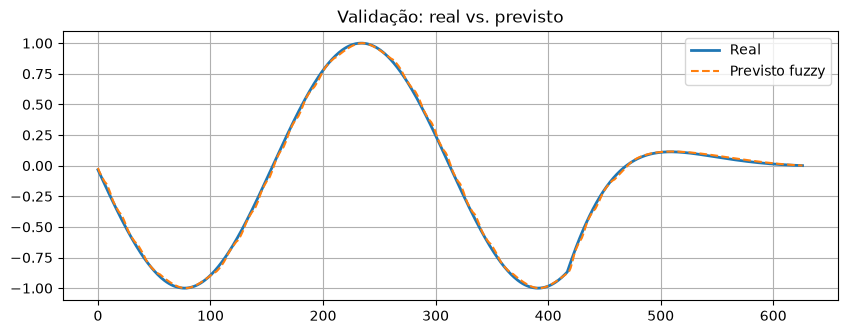

    MAE: 0.0127
   MAPE: 13.9508
   RMSE: 0.0163
     R2: 0.9992


In [14]:
y_pred = model.predict(X_val, prune=False, progress=False)

plt.plot(y_val, label="Real", lw=2)
plt.plot(y_pred, label="Previsto fuzzy", ls="--")
plt.title("Validação: real vs. previsto")
plt.legend(); plt.show()

for nome, valor in model.score(y_pred=y_pred, y_true=y_val).items():
    print(f"  {nome:>5}: {valor:.4f}")

E o erro ao longo do tempo:

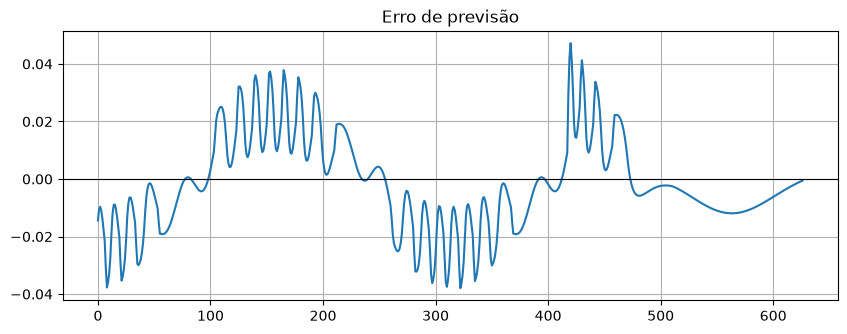

In [15]:
plt.plot(y_val - y_pred)
plt.title("Erro de previsão")
plt.axhline(0, color="k", lw=0.8)
plt.show()

---
## 7. Aplicando nos seus dados

O formato esperado é sempre o mesmo:

- `X` → shape `(n_amostras, n_variaveis)`
- `y` → shape `(n_amostras,)`

```python
model = FuzzyTSModel(
    input_names=["temperatura", "vento"],
    output_name="chuva",
    N=5,
    input_range="auto",      # deriva a faixa de cada variável dos dados
    output_range="auto",
)
model.fit(X, y)
print(model.explain())
```

Use `examples/02_seus_dados.py` como ponto de partida.

**Para escolher N:** comece em 5–7 e compare o erro de validação.


In [16]:
for N in (2, 4, 6, 8):
    m = FuzzyTSModel(["a", "b", "c"], "y", N=N,
                     input_range=[-1.5, 1.5], output_range=[-1.5, 1.5])
    m.fit(X_treino, y_treino, progress=False)
    pred = m.predict(X_val[:250], prune=False, progress=False)
    r2 = m.score(y_pred=pred, y_true=y_val[:250])["R2"]
    print(f"N = {N}:  {len(m.explain()):>3} regras   R² = {r2:.4f}")

N = 2:   11 regras   R² = 0.9645


N = 4:   31 regras   R² = 0.9993


N = 6:   41 regras   R² = 0.9994


N = 8:   51 regras   R² = 0.9983


---
## Além de Wang-Mendel

O pacote traz extensões que **não** fazem parte do método original:

| Recurso | O que faz |
|---|---|
| `predict(X, prune=True)` | remove regras pouco usadas e de baixo impacto durante a predição |
| `partial_fit(xi, yi)` | atualiza a base com uma amostra nova (aprendizado incremental) |
| `predict_and_update(...)` | prevê em blocos e reaprende quando o erro passa de um limiar |
| `max_rules` | limita o tamanho da base; a regra mais fraca dá lugar a uma mais forte |

Úteis quando a série muda de comportamento ao longo do tempo — o caso do terceiro
trecho da nossa série, que é amortecido.

---

## Resumo

1. Dividir cada variável em **2N+1 regiões** fuzzy
2. Cada amostra gera **uma regra**, pela região de maior pertinência
3. Cada regra recebe um **peso** (produto dos graus)
4. Em caso de conflito, **vence a de maior peso**

O resultado é um modelo que prevê **e se explica**.
